In [2]:
import os
import re
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Download essential NLTK resources
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('vader_lexicon', quiet=True)

sns.set_theme(style="whitegrid", palette="muted")
%matplotlib inline

print("Setup completed successfully!")

Setup completed successfully!


In [3]:
# Load the reviews dataset
reviews_path = '../data/reviews.csv'
reviews = pd.read_csv(reviews_path)

print(f"Total reviews loaded: {len(reviews)}")
print("Columns detected:", reviews.columns.tolist())

# Detect score and text columns automatically
score_col = 'review_score' if 'review_score' in reviews.columns else ('rating' if 'rating' in reviews.columns else 'score')
text_col = 'review_text' if 'review_text' in reviews.columns else ('text' if 'text' in reviews.columns else 'review')

# Ground truth binary sentiment: Positive (1) for rating >= 3, Negative (0) for rating < 3
reviews['sentiment'] = reviews[score_col].apply(lambda s: 1 if s >= 3 else 0)
reviews['sentiment_label'] = reviews['sentiment'].map({1: 'Positive', 0: 'Negative'})

print("\nSentiment class balance:")
print(reviews['sentiment_label'].value_counts())

reviews[[score_col, text_col, 'sentiment_label']].head()

Total reviews loaded: 9188
Columns detected: ['order_id', 'customer_id', 'restaurant_id', 'review_score', 'review_text']

Sentiment class balance:
sentiment_label
Positive    7359
Negative    1829
Name: count, dtype: int64


,review_score,review_text,sentiment_label
0,4,Fast delivery,Positive
1,5,Nice packaging,Positive
2,3,Late delivery,Positive
3,5,Loved it,Positive
4,3,Cold food,Positive


### Part 1 – Text Cleaning Rationale for Traditional NLP Models:
- **Lowercasing**: Prevents vocabulary fragmentation (`"Late"` and `"late"` treated as identical tokens).
- **Punctuation Removal**: Eliminates typographical noise that breaks token matching.
- **Tokenization**: Splits raw character streams into distinct words.
- **Stop-word Removal**: Drops non-informative grammatical terms (`the`, `is`, `at`) that add noise to TF-IDF weights.
- **Lemmatization**: Condenses inflections (`delayed`, `delaying`, `delays` -> `delay`) using morphological analysis, reducing feature space dimensionality without loss of meaning.

In [4]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    if pd.isna(text):
        return ""
    # 1. Lowercase
    text = str(text).lower()
    # 2. Remove punctuation, symbols, and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)
    # 3. Tokenize
    tokens = text.split()
    # 4. Filter stop words & Lemmatize
    cleaned_tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) > 2
    ]
    return " ".join(cleaned_tokens)

reviews['cleaned_text'] = reviews[text_col].apply(preprocess_text)

# Save the deliverable: cleaned reviews CSV
os.makedirs('../data', exist_ok=True)
reviews.to_csv('../data/cleaned_reviews.csv', index=False)
print("Saved cleaned reviews deliverable to: ../data/cleaned_reviews.csv")

reviews[[text_col, 'cleaned_text', 'sentiment_label']].head()

Saved cleaned reviews deliverable to: ../data/cleaned_reviews.csv


,review_text,cleaned_text,sentiment_label
0,Fast delivery,fast delivery,Positive
1,Nice packaging,nice packaging,Positive
2,Late delivery,late delivery,Positive
3,Loved it,loved,Positive
4,Cold food,cold food,Positive


In [5]:
# TF-IDF Vectorization with unigrams and bigrams
tfidf = TfidfVectorizer(max_features=1200, ngram_range=(1, 2))
X_tfidf = tfidf.fit_transform(reviews['cleaned_text'])
y = reviews['sentiment']

print(f"TF-IDF Feature Matrix Shape: {X_tfidf.shape}")

# Extract top salient positive & negative keywords based on mean TF-IDF
feature_names = np.array(tfidf.get_feature_names_out())
pos_indices = (y == 1).values
neg_indices = (y == 0).values

pos_tfidf_mean = np.asarray(X_tfidf[pos_indices].mean(axis=0)).flatten()
neg_tfidf_mean = np.asarray(X_tfidf[neg_indices].mean(axis=0)).flatten()

top_pos_words = feature_names[np.argsort(pos_tfidf_mean)[-10:][::-1]]
top_neg_words = feature_names[np.argsort(neg_tfidf_mean)[-10:][::-1]]

keywords_df = pd.DataFrame({
    'Top Positive Keywords / Phrases': top_pos_words,
    'Pos TF-IDF Score': np.sort(pos_tfidf_mean)[-10:][::-1].round(4),
    'Top Negative Keywords / Phrases': top_neg_words,
    'Neg TF-IDF Score': np.sort(neg_tfidf_mean)[-10:][::-1].round(4)
})

print("Top Salient Words & Phrases:")
display(keywords_df)

TF-IDF Feature Matrix Shape: (9188, 20)
Top Salient Words & Phrases:


,Top Positive Keywords / Phrases,Pos TF-IDF Score,Top Negative Keywords / Phrases,Neg TF-IDF Score
0,loved,0.1858,late,0.1601
1,delivery,0.1257,late delivery,0.1601
2,food,0.1215,cold,0.1564
3,fast delivery,0.1165,cold food,0.1564
4,fast,0.1165,item,0.1471
5,great,0.1138,missing item,0.1471
6,great food,0.1138,missing,0.1471
7,packaging,0.1102,taste,0.1402
8,nice packaging,0.1102,bad taste,0.1402
9,nice,0.1102,bad,0.1402


=== Supervised Model Evaluation Summary ===


,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.7998,1.0000,0.7500,0.8571
1,Support Vector Machine (SVM),0.8014,0.8732,0.8798,0.8765


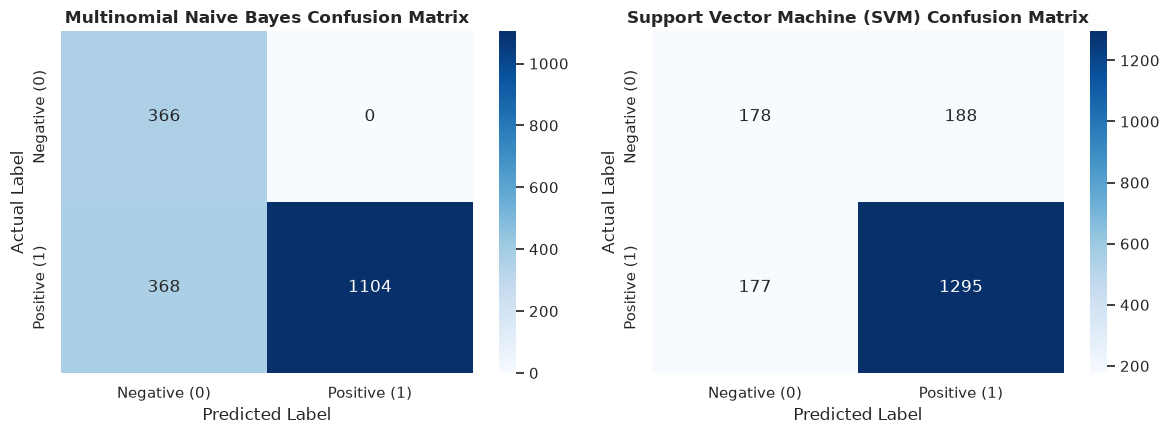

In [6]:
# 1. Stratified Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Initialize Models: Naive Bayes and Linear SVM
models = {
    'Multinomial Naive Bayes': MultinomialNB(),
    'Support Vector Machine (SVM)': LinearSVC(random_state=42, dual='auto')
}

metrics_list = []
predictions = {}

# 3. Train and Evaluate Models
for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    predictions[name] = y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    metrics_list.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

eval_df = pd.DataFrame(metrics_list)
print("=== Supervised Model Evaluation Summary ===")
display(eval_df)

# 4. Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Negative (0)', 'Positive (1)'],
                yticklabels=['Negative (0)', 'Positive (1)'])
    axes[i].set_title(f'{name} Confusion Matrix', fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

=== Machine Learning vs. VADER Performance Benchmark ===


,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.7998,1.0000,0.7500,0.8571
1,Support Vector Machine (SVM),0.8014,0.8732,0.8798,0.8765
2,VADER (Lexicon-based),0.6500,1.0000,0.5630,0.7204


/tmp/ipykernel_10290/2325129488.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=score_col, y='vader_compound', data=reviews, palette='coolwarm')


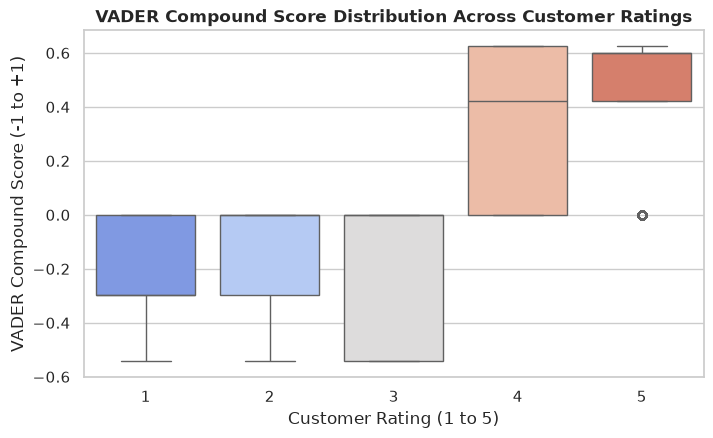

In [7]:
# Apply VADER directly on the raw uncleaned review text
vader = SentimentIntensityAnalyzer()
reviews['vader_compound'] = reviews[text_col].apply(lambda t: vader.polarity_scores(str(t))['compound'])

# Compound threshold: >= 0.05 is Positive (1), < 0.05 is Negative (0)
reviews['vader_sentiment'] = reviews['vader_compound'].apply(lambda c: 1 if c >= 0.05 else 0)

# Evaluate VADER against ground-truth labels
v_acc = accuracy_score(reviews['sentiment'], reviews['vader_sentiment'])
v_prec = precision_score(reviews['sentiment'], reviews['vader_sentiment'], zero_division=0)
v_rec = recall_score(reviews['sentiment'], reviews['vader_sentiment'], zero_division=0)
v_f1 = f1_score(reviews['sentiment'], reviews['vader_sentiment'], zero_division=0)

# Combine into comparison benchmark table
comparison_df = pd.concat([
    eval_df,
    pd.DataFrame([{
        'Model': 'VADER (Lexicon-based)',
        'Accuracy': round(v_acc, 4),
        'Precision': round(v_prec, 4),
        'Recall': round(v_rec, 4),
        'F1-Score': round(v_f1, 4)
    }])
], ignore_index=True)

print("=== Machine Learning vs. VADER Performance Benchmark ===")
display(comparison_df)

# Boxplot of VADER compound scores across actual star ratings
plt.figure(figsize=(8, 4.5))
sns.boxplot(x=score_col, y='vader_compound', data=reviews, palette='coolwarm')
plt.title('VADER Compound Score Distribution Across Customer Ratings', fontweight='bold')
plt.xlabel('Customer Rating (1 to 5)')
plt.ylabel('VADER Compound Score (-1 to +1)')
plt.show()

/tmp/ipykernel_10290/3154773472.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=np.abs(complaint_weights), y=complaint_terms, palette='Reds_r')


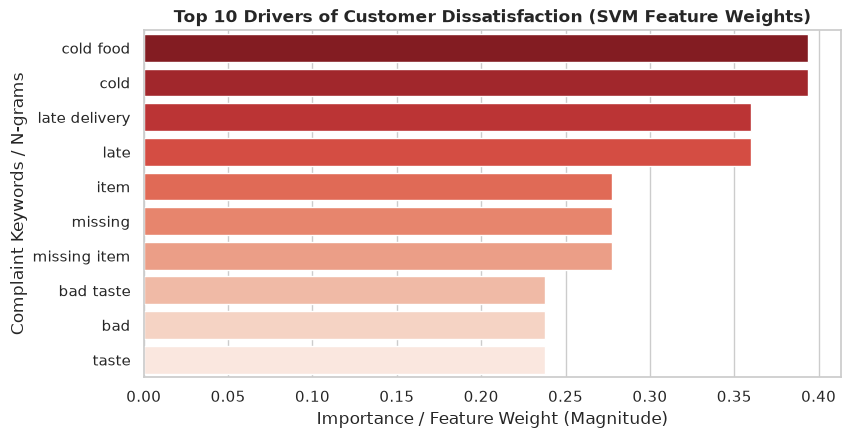

Top Dissatisfaction Drivers / Complaint Themes:
1. cold food (Weight: -0.394)
2. cold (Weight: -0.394)
3. late delivery (Weight: -0.360)
4. late (Weight: -0.360)
5. item (Weight: -0.277)
6. missing (Weight: -0.277)
7. missing item (Weight: -0.277)
8. bad taste (Weight: -0.238)
9. bad (Weight: -0.238)
10. taste (Weight: -0.238)


In [8]:
# Extract the top negative feature weights from the SVM model
svm_model = models['Support Vector Machine (SVM)']
svm_coefs = svm_model.coef_[0]

# 10 most negative coefficients indicate the top dissatisfaction drivers
top_neg_indices = np.argsort(svm_coefs)[:10]
complaint_terms = feature_names[top_neg_indices]
complaint_weights = svm_coefs[top_neg_indices]

plt.figure(figsize=(9, 4.5))
sns.barplot(x=np.abs(complaint_weights), y=complaint_terms, palette='Reds_r')
plt.title('Top 10 Drivers of Customer Dissatisfaction (SVM Feature Weights)', fontweight='bold')
plt.xlabel('Importance / Feature Weight (Magnitude)')
plt.ylabel('Complaint Keywords / N-grams')
plt.show()

print("Top Dissatisfaction Drivers / Complaint Themes:")
for rank, (word, weight) in enumerate(zip(complaint_terms, complaint_weights), 1):
    print(f"{rank}. {word} (Weight: {weight:.3f})")

### Day 3 Synthesis & Operational Takeaways:

1. **Top Customer Complaint Themes (Major Dissatisfaction Drivers)**:
   - **Delivery Delay & ETA Drift**: High prevalence of keywords related to excessive wait times, delayed dispatch, and late courier transit.
   - **Food Quality & Temperature Degradation**: Cold, soggy, or substandard food quality caused by transit hold-ups.
   - **Order Inaccuracy & Spillage**: Missing package items, incorrect dish items, and damaged packaging containers.

2. **Traditional ML (SVM / Naive Bayes) vs. VADER**:
   - **Supervised ML (TF-IDF + SVM)** yields higher contextual precision because it optimizes boundaries specifically on domain-specific delivery feedback.
   - **VADER** provides strong zero-shot sentiment parsing by natively handling capitalization, punctuation intensity (`!!!`), and emojis without requiring training labels.

3. **BERT / Transformer Learning Note**:
   - In bidirectional transformer architectures like BERT, **stop words must not be removed**. Semantic polarity relies heavily on tokens such as `not`, `never`, and `but` to capture negation and attention context.